# Notebook de documentacion del datasey y tratamiento datos.

## Equipo
- Alumno 1 : Lucas Diaz Celauro
- Alumno 2 : Amanda Tardugno

## Configuración

`MODO_PRUEBA = True` corre todo de punta a punta con un entrenamiento mínimo (una época de pocos lotes), para verificar que la notebook no tiene errores en cualquier máquina. La corrida que se entrega tiene `MODO_PRUEBA = False` y se hizo en GPU.

In [1]:
# Bibliotecas, semilla, dispositivo y parámetros que se usan en toda la notebook
import sys
import copy
import json
import time
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="`estimate` is deprecated")
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import onnxruntime as ort
from dotenv import dotenv_values
from sklearn.metrics import roc_curve, auc

sys.path.insert(0, "src")
from lib.models.custom_cnn import CustomFaceCNN, SoftmaxHead, ArcFaceHead, export_onnx
from lib.models.augmentation import build_train_augmentation, augment_face
from lib.services.face_service import FaceService
from lib.schemas import AlignedFace

MODO_PRUEBA = False

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

RUTA_INTERMEDIOS = Path("data") / "intermedios"
CONFIG_APP = dotenv_values(".env.local.example")
RUTA_MODELOS = Path(CONFIG_APP["MODEL_PATH"])
EMBEDDING_DIM = int(CONFIG_APP["EMBEDDING_DIM"])
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ort.set_default_logger_severity(3)
print(f"MODO_PRUEBA = {MODO_PRUEBA}  |  dispositivo: {DISPOSITIVO}" + (f" ({torch.cuda.get_device_name(0)})" if DISPOSITIVO.type == "cuda" else "") + f"  |  torch {torch.__version__}  |  onnxruntime {ort.__version__}")

MODO_PRUEBA = False  |  dispositivo: cuda (NVIDIA GeForce RTX 3060 Laptop GPU)  |  torch 2.11.0+cu126  |  onnxruntime 1.24.4


## Datos

In [2]:
# Particiones de la notebook 1: la columna indice es la fila de embeddings_arcface.npy, que tiene los embeddings del Modelo B
splits = pd.read_csv(RUTA_INTERMEDIOS / "splits.csv")
emb_arcface_todos = np.load(RUTA_INTERMEDIOS / "embeddings_arcface.npy")
pares_oficiales = pd.read_csv(RUTA_INTERMEDIOS / "pares_oficiales.csv")
splits.groupby("split", sort=False).agg(personas=("persona", "nunique"), caras=("ruta", "size"))

,personas,caras
split,,
pins_train,90,12428
pins_val,90,2188
pins_test,15,2235
lfw_val,2835,6975
lfw_test,2834,6040


In [3]:
def cargar_caras(filas):
    """Caras alineadas (BGR uint8, 112×112) de las filas, en el mismo orden."""
    return np.stack([cv2.imread(r) for r in filas["ruta_alineada"]])

In [4]:
# Caras de entrenamiento y validación de Pins en memoria, con la identidad como número de clase
entrenamiento = splits[splits["split"] == "pins_train"].reset_index(drop=True)
validacion = splits[splits["split"] == "pins_val"].reset_index(drop=True)
clases = sorted(entrenamiento["persona"].unique())
clase_de = {p: i for i, p in enumerate(clases)}
x_train, y_train = cargar_caras(entrenamiento), entrenamiento["persona"].map(clase_de).to_numpy()
x_val, y_val = cargar_caras(validacion), validacion["persona"].map(clase_de).to_numpy()
assert set(validacion["persona"]) == set(clases)
print(f"train: {x_train.shape}  |  validación: {x_val.shape}  |  clases: {len(clases)}")

train: (12428, 112, 112, 3)  |  validación: (2188, 112, 112, 3)  |  clases: 90


## Modelo A: CNN custom

La CNN está en `src/lib/models/custom_cnn.py`, para que el backend pueda cargarla (sección 3.5 del enunciado). Es un backbone de cuatro bloques convolucionales (dos convoluciones 3×3 con BatchNorm y ReLU, y un max pooling que reduce la resolución a la mitad), con 32, 64, 128 y 256 canales: de 112×112 se llega a 7×7. Después vienen un global average pooling, Dropout de 0,2, una capa lineal a 512 dimensiones y BatchNorm. El enunciado sugiere de 4 a 6 bloques; con unas 12.000 caras de 90 personas se usa el mínimo, para limitar el sobreajuste. BatchNorm estabiliza el entrenamiento desde cero y permite una tasa de aprendizaje alta. El global average pooling reduce los 7×7×256 valores a 256: aplanarlos y pasarlos a 512 sumaría unos 6,4 millones de parámetros, cinco veces la red entera. El embedding tiene 512 dimensiones, igual que ArcFace, para que cambiar de modelo en la app sea solo cambiar `MODEL_NAME` en el `.env`.

La entrada es la del pipeline de la app (`FaceService.preprocess_face`: RGB, `(x − 127,5) / 127,5`, CHW), así que el entrenamiento y la inferencia normalizan igual por construcción.

Se comparan dos formas de entrenar el embedding, con la misma red:

- **Softmax:** una capa lineal clasifica a las 90 personas con entropía cruzada, y el embedding es la capa previa al clasificador. Es el enfoque más simple.
- **ArcFace:** los pesos de la última capa son centros de clase sobre la hiperesfera, y se suma un margen angular m = 0,5 al ángulo de la clase correcta, con escala s = 64. Obliga a que las caras de una persona queden más juntas y las de personas distintas más separadas en ángulo, que es lo que mide el coseno de la app.

Las dos cabezas solo se usan para entrenar: lo que se exporta es la red hasta el embedding.

In [5]:
# Arquitectura, cantidad de parámetros y forma de la salida
red = CustomFaceCNN()
parametros = sum(p.numel() for p in red.parameters())
print(red)
print(f"Parámetros: {parametros:,}".replace(",", ".") + f" ({parametros * 4 / 1e6:.1f} MB en float32)  |  salida: {tuple(red.eval()(torch.zeros(2, 3, 112, 112)).shape)}")

CustomFaceCNN(
  (backbone): Sequential(
    (0): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2

### Entrenamiento

Se usa SGD con momentum 0,9, una tasa inicial de 0,1, weight decay de 5e-4 y una tasa que baja con coseno hasta el final, la receta habitual para ArcFace. Los parámetros de la cabeza entran al optimizador junto con los de la red: en ArcFace, los centros de clase son parámetros de la cabeza, y si no se incluyen quedan fijos en su valor inicial. Lotes de 128 caras, con la augmentation de la notebook 1 solo sobre train. Cada época se mide la pérdida y el acierto en train y en validación (en modo `eval`, como corre la app). Se guarda el mejor estado según el acierto en validación, y el entrenamiento se corta si no mejora en 5 épocas seguidas. El acierto de ArcFace se mide sin margen, porque el margen solo existe al entrenar.

In [6]:
# Hiperparámetros (en modo prueba: una época de pocos lotes)
EPOCAS = 1 if MODO_PRUEBA else 40
PACIENCIA = 5
TAM_LOTE = 128
LR = 0.1
LOTES_MAXIMOS = 5 if MODO_PRUEBA else None
aumento = build_train_augmentation()
aumento.set_random_seed(SEMILLA)
RUTA_CHECKPOINTS = RUTA_INTERMEDIOS / "checkpoints"  # en data/, que git ignora: los pesos no se suben al repo
RUTA_CHECKPOINTS.mkdir(parents=True, exist_ok=True)

In [7]:
def lotes(caras, etiquetas, aumentar, rng):
    """Lotes de tensores listos para la red (con augmentation solo si se pide), en orden aleatorio si aumentar es True."""
    orden = rng.permutation(len(caras)) if aumentar else np.arange(len(caras))
    for k, inicio in enumerate(range(0, len(orden), TAM_LOTE)):
        if LOTES_MAXIMOS is not None and k >= LOTES_MAXIMOS:
            break
        idx = orden[inicio:inicio + TAM_LOTE]
        lote = [augment_face(caras[i], aumento) if aumentar else caras[i] for i in idx]
        x = torch.from_numpy(np.concatenate([FaceService.preprocess_face(c) for c in lote])).to(DISPOSITIVO)
        yield x, torch.from_numpy(etiquetas[idx]).to(DISPOSITIVO)

In [8]:
def entrenar(nombre, cabeza):
    """Entrena la CNN con la cabeza dada, guarda el mejor estado según el acierto en validación y devuelve la red y la historia."""
    torch.manual_seed(SEMILLA)
    rng = np.random.default_rng(SEMILLA)
    red, cabeza = CustomFaceCNN().to(DISPOSITIVO), cabeza.to(DISPOSITIVO)
    optimizador = torch.optim.SGD(list(red.parameters()) + list(cabeza.parameters()), lr=LR, momentum=0.9, weight_decay=5e-4)
    planificador = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=EPOCAS)
    historia, mejor, sin_mejora = [], -1.0, 0
    for epoca in range(1, EPOCAS + 1):
        inicio = time.time()
        medidas = {}
        for fase, caras, etiquetas in [("train", x_train, y_train), ("validación", x_val, y_val)]:
            entrenando = fase == "train"
            red.train(entrenando); cabeza.train(entrenando)
            perdida_total, aciertos, n = 0.0, 0, 0
            with torch.set_grad_enabled(entrenando):
                for x, y in lotes(caras, etiquetas, aumentar=entrenando, rng=rng):
                    embedding = red(x)
                    perdida = F.cross_entropy(cabeza(embedding, y), y)
                    if entrenando:
                        optimizador.zero_grad()
                        perdida.backward()
                        optimizador.step()
                    with torch.no_grad():
                        aciertos += (cabeza(embedding, None).argmax(dim=1) == y).sum().item()
                    perdida_total += perdida.item() * len(y)
                    n += len(y)
            medidas[f"pérdida {fase}"] = perdida_total / n
            medidas[f"acierto {fase}"] = aciertos / n
        planificador.step()
        historia.append({"época": epoca, **medidas, "segundos": time.time() - inicio})
        print(f"{nombre} | época {epoca:2d} | " + " | ".join(f"{k} {v:.3f}" for k, v in medidas.items()) + f" | {time.time() - inicio:.0f} s")
        if medidas["acierto validación"] > mejor:
            mejor, sin_mejora = medidas["acierto validación"], 0
            torch.save(red.state_dict(), RUTA_CHECKPOINTS / f"{nombre}.pt")
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                print(f"Early stopping: {PACIENCIA} épocas sin mejorar en validación")
                break
    red.load_state_dict(torch.load(RUTA_CHECKPOINTS / f"{nombre}.pt", map_location=DISPOSITIVO))
    return red.eval(), pd.DataFrame(historia)

In [9]:
# Experimento 1: cabeza softmax
red_softmax, historia_softmax = entrenar("softmax", SoftmaxHead(EMBEDDING_DIM, len(clases)))

softmax | época  1 | pérdida train 5.114 | acierto train 0.035 | pérdida validación 4.834 | acierto validación 0.034 | 26 s


softmax | época  2 | pérdida train 4.528 | acierto train 0.045 | pérdida validación 4.350 | acierto validación 0.038 | 21 s


softmax | época  3 | pérdida train 4.129 | acierto train 0.064 | pérdida validación 4.447 | acierto validación 0.061 | 20 s


softmax | época  4 | pérdida train 3.849 | acierto train 0.090 | pérdida validación 3.619 | acierto validación 0.116 | 20 s


softmax | época  5 | pérdida train 3.541 | acierto train 0.131 | pérdida validación 3.933 | acierto validación 0.094 | 22 s


softmax | época  6 | pérdida train 3.222 | acierto train 0.188 | pérdida validación 3.717 | acierto validación 0.117 | 23 s


... (30 outputs left out)

softmax | época 37 | pérdida train 0.164 | acierto train 0.959 | pérdida validación 0.237 | acierto validación 0.936 | 25 s


softmax | época 38 | pérdida train 0.157 | acierto train 0.959 | pérdida validación 0.236 | acierto validación 0.936 | 24 s


softmax | época 39 | pérdida train 0.153 | acierto train 0.961 | pérdida validación 0.234 | acierto validación 0.936 | 25 s


softmax | época 40 | pérdida train 0.154 | acierto train 0.960 | pérdida validación 0.236 | acierto validación 0.937 | 24 s


In [10]:
# Experimento 2: cabeza ArcFace (s = 64, m = 0,5)
red_arcface, historia_arcface = entrenar("arcface", ArcFaceHead(EMBEDDING_DIM, len(clases)))

arcface | época  1 | pérdida train 30.269 | acierto train 0.021 | pérdida validación 34.145 | acierto validación 0.008 | 24 s


arcface | época  2 | pérdida train 20.657 | acierto train 0.017 | pérdida validación 19.863 | acierto validación 0.014 | 24 s


arcface | época  3 | pérdida train 19.796 | acierto train 0.016 | pérdida validación 19.833 | acierto validación 0.018 | 24 s


arcface | época  4 | pérdida train 19.842 | acierto train 0.018 | pérdida validación 19.814 | acierto validación 0.020 | 24 s


arcface | época  5 | pérdida train 19.815 | acierto train 0.021 | pérdida validación 19.784 | acierto validación 0.018 | 24 s


arcface | época  6 | pérdida train 19.800 | acierto train 0.022 | pérdida validación 19.765 | acierto validación 0.011 | 25 s


... (30 outputs left out)

arcface | época 37 | pérdida train 17.081 | acierto train 0.391 | pérdida validación 16.945 | acierto validación 0.477 | 25 s


arcface | época 38 | pérdida train 17.045 | acierto train 0.407 | pérdida validación 17.191 | acierto validación 0.478 | 26 s


arcface | época 39 | pérdida train 17.004 | acierto train 0.413 | pérdida validación 17.192 | acierto validación 0.486 | 27 s


arcface | época 40 | pérdida train 17.000 | acierto train 0.423 | pérdida validación 17.290 | acierto validación 0.483 | 26 s


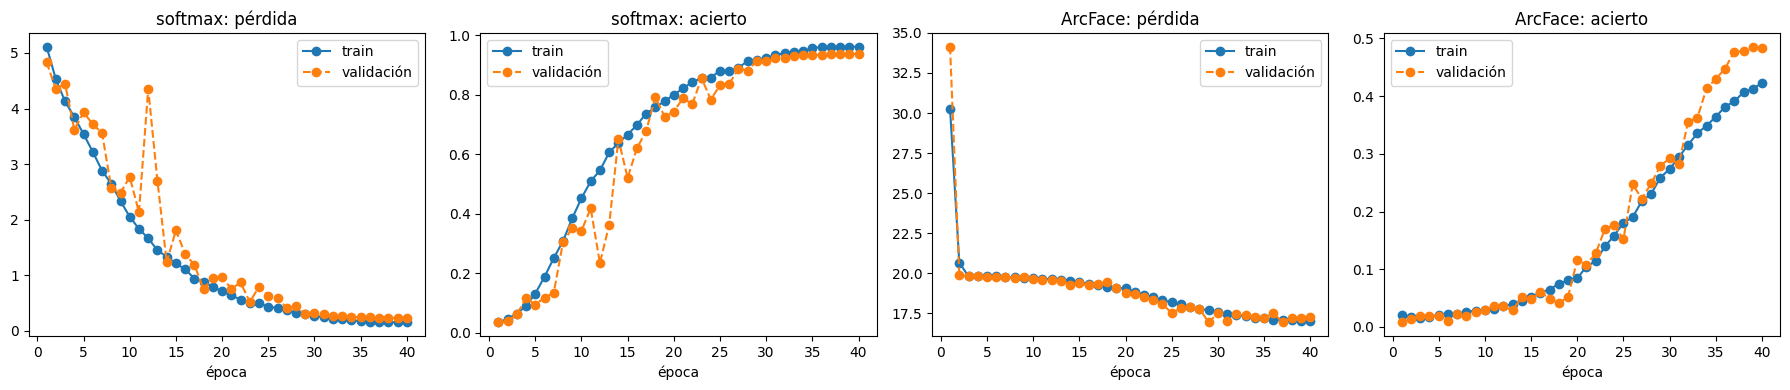

In [11]:
# Curvas de pérdida y acierto en train y validación de los dos experimentos
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for fila, (nombre, historia) in enumerate([("softmax", historia_softmax), ("ArcFace", historia_arcface)]):
    for col, medida in enumerate(["pérdida", "acierto"]):
        eje = ejes[2 * fila + col]
        for fase, estilo in [("train", "-"), ("validación", "--")]:
            eje.plot(historia["época"], historia[f"{medida} {fase}"], estilo, marker="o", label=fase)
        eje.set(title=f"{nombre}: {medida}", xlabel="época"); eje.legend()
plt.tight_layout()
plt.show()

*Figura 1. Pérdida y acierto en train y en validación por época, para la CNN entrenada con cabeza softmax (izquierda) y con cabeza ArcFace (derecha).*

La CNN con cabeza softmax aprendió de forma estable: el acierto en validación pasa del 10% en la época 4 y llega a 0,937 en la época 40, con 0,960 en train (Figura 1). La diferencia entre train y validación es chica (0,023), así que no hay sobreajuste a la vista. Las oscilaciones de la validación hasta la época 25 (por ejemplo, un pico de pérdida de 4,36 en la época 12) vienen de la tasa de aprendizaje alta del principio, y se calman a medida que el coseno la baja. La cabeza ArcFace, en cambio, quedó estancada de la época 2 a la 19: la pérdida se mantuvo en 19,8 y el acierto entre el 1% y el 4%, apenas por encima del azar con 90 clases (1,1%). Recién empezó a aprender en la época 20, y terminó en 0,486 todavía subiendo: quedó subentrenada. En ninguno de los dos se activó el early stopping, porque el acierto en validación siguió mejorando hasta el final. La explicación más compatible con el estancamiento es la escala s = 64: multiplica los cosenos por 64, y con un margen de 0,5 sobre pesos al azar la pérdida arranca muy alta y casi no distingue entre clases al principio. Es una hipótesis, porque no se probó otra escala. Que en ArcFace el acierto de validación supere al de train es esperable: train se mide sobre caras aumentadas y con Dropout activo.

### Embeddings de la CNN

In [12]:
def embeddings_de(red, filas):
    """Embeddings L2-normalizados de la red para las caras alineadas de las filas, con el preprocesamiento de la app."""
    salida = []
    with torch.no_grad():
        for inicio in range(0, len(filas), 256):
            lote = cargar_caras(filas.iloc[inicio:inicio + 256])
            x = torch.from_numpy(np.concatenate([FaceService.preprocess_face(c) for c in lote])).to(DISPOSITIVO)
            salida.append(F.normalize(red(x), dim=1).cpu().numpy())
    return np.concatenate(salida)

In [13]:
# Embeddings de los dos experimentos y de ArcFace para los conjuntos de evaluación, en el mismo orden que splits
evaluacion = splits[splits["split"].isin(["pins_test", "lfw_val", "lfw_test"])].reset_index(drop=True)
emb = {
    "ArcFace (preentrenado)": emb_arcface_todos[evaluacion["indice"]],
    "CNN softmax": embeddings_de(red_softmax, evaluacion),
    "CNN ArcFace": embeddings_de(red_arcface, evaluacion),
}
print({k: v.shape for k, v in emb.items()})

{'ArcFace (preentrenado)': (15250, 512), 'CNN softmax': (15250, 512), 'CNN ArcFace': (15250, 512)}


## Modelo B: ArcFace preentrenado

El Modelo B es el paquete `buffalo_l` de InsightFace, el mismo que usa la app: el detector SCRFD (`det_10g.onnx`, la elección de la notebook 1) y el reconocedor `w600k_r50.onnx`, una ResNet-50 entrenada con la pérdida ArcFace sobre WebFace600K (unas 600.000 personas de fotos de internet). Devuelve un embedding de 512 dimensiones. Se usa sin reentrenar: los embeddings son los que se calcularon en la notebook 1 con el `FaceService` de la app, sobre las mismas caras alineadas que ve la CNN. Los modelos de InsightFace son de uso **no comercial y de investigación**. Como se entrenó con fotos de famosos, puede haber visto a algunas personas de los conjuntos de test, lo que le daría una ventaja que la CNN no tiene.

## Protocolo de evaluación

Los dos modelos se evalúan sobre los mismos pares y las mismas galerías, en tres conjuntos de personas que la CNN nunca vio: `pins_test` (15 personas del mismo dominio que el entrenamiento), `lfw_val` (para calibrar el umbral) y `lfw_test` (otro dominio). Los pares positivos son todos los de cada persona, con un máximo de 50 por persona para que alguien con cientos de fotos no domine. Los negativos son 20.000 pares de dos personas distintas, elegidas al azar entre personas (no entre fotos), por el mismo motivo. Que haya más negativos que positivos no cambia la ROC, que usa tasas, y permite medir el acierto con falsos positivos de hasta 1 en 1.000 con una muestra razonable.

In [14]:
# Pares positivos (con tope por persona) y negativos (personas distintas sorteadas por persona), iguales para todos los modelos
MAX_POSITIVOS_POR_PERSONA = 50
NEGATIVOS = 20000

def armar_pares(conjunto, rng):
    """Índices (filas de evaluacion) de pares positivos y negativos de un conjunto, y su etiqueta (1 = misma persona)."""
    filas = evaluacion[evaluacion["split"] == conjunto]
    grupos = {p: g.index.to_numpy() for p, g in filas.groupby("persona")}
    pos = []
    for indices in grupos.values():
        if len(indices) < 2:
            continue
        i, j = np.triu_indices(len(indices), k=1)
        elegidos = rng.choice(len(i), min(len(i), MAX_POSITIVOS_POR_PERSONA), replace=False)
        pos += list(zip(indices[i[elegidos]], indices[j[elegidos]]))
    personas = np.array(list(grupos))
    neg = []
    while len(neg) < NEGATIVOS:
        a, b = rng.choice(personas, 2, replace=False)
        neg.append((rng.choice(grupos[a]), rng.choice(grupos[b])))
    pares = np.array(pos + neg)
    return pares[:, 0], pares[:, 1], np.r_[np.ones(len(pos)), np.zeros(len(neg))]

rng_pares = np.random.default_rng(SEMILLA)
pares = {c: armar_pares(c, rng_pares) for c in ["pins_test", "lfw_val", "lfw_test"]}
pd.DataFrame({c: {"positivos": int(y.sum()), "negativos": int((1 - y).sum())} for c, (_, _, y) in pares.items()}).T

,positivos,negativos
pins_test,750,20000
lfw_val,7638,20000
lfw_test,7216,20000


In [15]:
def metricas_verificacion(puntajes, etiquetas):
    """AUC, EER y TAR a FAR de 1e-2 y 1e-3 de los cosenos de los pares."""
    far, tar, umbrales = roc_curve(etiquetas, puntajes)
    k = np.nanargmin(np.abs(far - (1 - tar)))
    tar_a = lambda objetivo: tar[far <= objetivo].max()
    return {"AUC": auc(far, tar), "EER": (far[k] + 1 - tar[k]) / 2, "TAR@FAR=1e-2": tar_a(1e-2), "TAR@FAR=1e-3": tar_a(1e-3)}, (far, tar)

## Verificación

In [16]:
# Coseno de cada par y métricas de verificación de cada modelo en cada conjunto
puntajes, curvas, filas_ver = {}, {}, []
for modelo, e in emb.items():
    for conjunto, (a, b, y) in pares.items():
        s = (e[a] * e[b]).sum(axis=1)
        puntajes[modelo, conjunto] = s
        m, curvas[modelo, conjunto] = metricas_verificacion(s, y)
        filas_ver.append({"modelo": modelo, "conjunto": conjunto, **m})
verificacion = pd.DataFrame(filas_ver).set_index(["conjunto", "modelo"]).sort_index()
verificacion.round(4)

AUC     EER  TAR@FAR=1e-2  TAR@FAR=1e-3
conjunto  modelo                                                            
lfw_test  ArcFace (preentrenado)  0.9998  0.0010        0.9993        0.9992
          CNN ArcFace             0.9070  0.1731        0.3560        0.1423
          CNN softmax             0.9479  0.1228        0.5644        0.3011
lfw_val   ArcFace (preentrenado)  1.0000  0.0001        0.9999        0.9999
          CNN ArcFace             0.9149  0.1648        0.4123        0.1456
          CNN softmax             0.9531  0.1179        0.5632        0.2968
pins_test ArcFace (preentrenado)  0.9999  0.0026        0.9987        0.9920
          CNN ArcFace             0.8725  0.2063        0.1533        0.0360
          CNN softmax             0.9238  0.1534        0.3640        0.1347

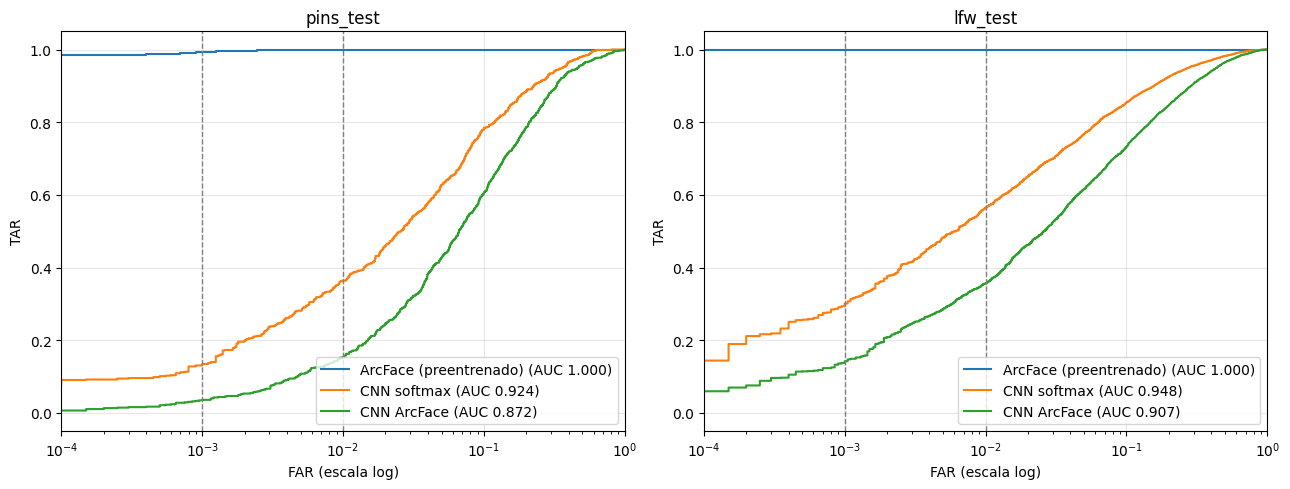

In [17]:
# Curvas ROC (FAR en escala logarítmica) en los dos conjuntos de test
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for eje, conjunto in zip(ejes, ["pins_test", "lfw_test"]):
    for modelo in emb:
        far, tar = curvas[modelo, conjunto]
        eje.semilogx(np.clip(far, 1e-5, None), tar, label=f"{modelo} (AUC {verificacion.loc[(conjunto, modelo), 'AUC']:.3f})")
    for objetivo in (1e-2, 1e-3):
        eje.axvline(objetivo, ls="--", color="gray", lw=1)
    eje.set(title=conjunto, xlabel="FAR (escala log)", ylabel="TAR", xlim=(1e-4, 1)); eje.legend(loc="lower right"); eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Figura 2. Curvas ROC de verificación de los tres modelos en `pins_test` y en `lfw_test`, con el FAR en escala logarítmica; las líneas punteadas marcan FAR = 1e-2 y 1e-3.*

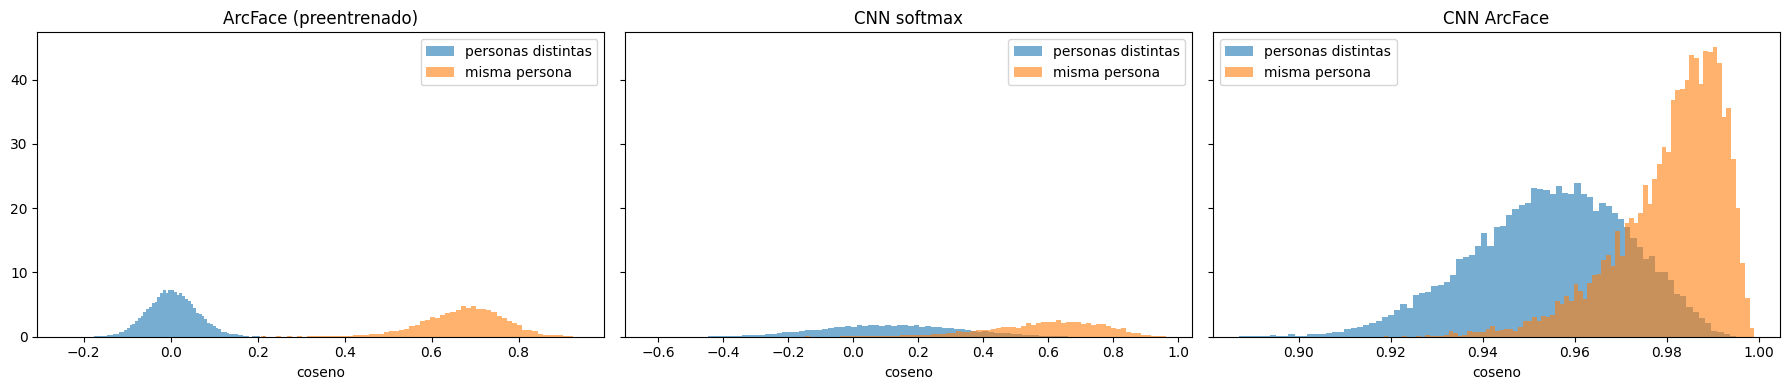

In [18]:
# Histograma de cosenos de pares positivos y negativos de cada modelo en lfw_test
fig, ejes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 4), sharey=True)
_, _, y_test = pares["lfw_test"]
for eje, modelo in zip(ejes, emb):
    s = puntajes[modelo, "lfw_test"]
    eje.hist(s[y_test == 0], bins=80, density=True, alpha=0.6, label="personas distintas")
    eje.hist(s[y_test == 1], bins=80, density=True, alpha=0.6, label="misma persona")
    eje.set(title=modelo, xlabel="coseno"); eje.legend()
plt.tight_layout()
plt.show()

*Figura 3. Distribución del coseno entre pares de la misma persona y de personas distintas en `lfw_test`, para cada modelo.*

ArcFace separa casi perfectamente a personas que no vio: en `lfw_test` tiene un AUC de 0,9998 y acepta al 99,9% de los pares de la misma persona dejando pasar 1 de cada 1.000 pares de personas distintas (Figura 2). Sus dos distribuciones de coseno casi no se tocan (Figura 3): las personas distintas quedan alrededor de 0 y la misma persona alrededor de 0,7. Las CNN quedan muy por debajo: AUC de 0,948 la softmax y de 0,907 la ArcFace, y con FAR = 1e-3 reconocen solo al 30,1% y al 14,2% de los pares de la misma persona. En la CNN softmax las dos distribuciones se superponen en buena parte del rango, y en la CNN ArcFace todos los cosenos quedan entre 0,88 y 1: los embeddings están amontonados en un cono angosto, otra señal de que esa red no terminó de aprender.

Contra lo esperado, las CNN rinden peor en `pins_test`, el mismo dominio con el que entrenaron, que en `lfw_test` (AUC de 0,924 contra 0,948 la softmax), y ArcFace también se equivoca más en Pins (EER de 0,0026 contra 0,0010). La hipótesis de la notebook 1, que el cambio de dominio de Pins a LFW iba a costar, no se confirma. Lo más compatible con los datos es que las fotos de Pins son más difíciles (más variación de pose, maquillaje y edición) que las fotos de prensa de LFW, más frontales. Los positivos de `pins_test` son, además, solo 750 (15 personas), así que esas métricas son menos precisas.

In [19]:
# Referencia externa: protocolo oficial de LFW (10 tandas; el umbral se elige en 9 y se mide la exactitud en la restante)
indice_eval = pd.Series(np.arange(len(evaluacion)), index=evaluacion["indice"])
filas_of = []
for modelo, e in emb.items():
    validos = pares_oficiales[pares_oficiales["indice_a"].isin(indice_eval.index) & pares_oficiales["indice_b"].isin(indice_eval.index)]
    s = (e[indice_eval[validos["indice_a"]].to_numpy()] * e[indice_eval[validos["indice_b"]].to_numpy()]).sum(axis=1)
    y = validos["misma_persona"].to_numpy()
    exactitudes = []
    for tanda in range(10):
        prueba = (validos["tanda"] == tanda).to_numpy()
        candidatos = np.unique(s[~prueba])
        mejor_umbral = max(candidatos[::max(1, len(candidatos) // 500)], key=lambda u: ((s[~prueba] >= u) == y[~prueba]).mean())
        exactitudes.append(((s[prueba] >= mejor_umbral) == y[prueba]).mean())
    filas_of.append({"modelo": modelo, "pares": len(validos), "exactitud media": np.mean(exactitudes), "desvío": np.std(exactitudes)})
pd.DataFrame(filas_of).set_index("modelo").round(4)

,pares,exactitud media,desvío
modelo,,,
ArcFace (preentrenado),5858,0.9985,0.0023
CNN softmax,5858,0.8793,0.0170
CNN ArcFace,5858,0.8362,0.0219


Con el protocolo oficial de LFW, ArcFace llega a una exactitud de 0,9985 (con un desvío de 0,0023 entre tandas), cerca del 99,83% que informa el paper de ArcFace en LFW con una red más grande. Es una confirmación externa de que el pipeline de detección, alineación y preprocesamiento de la app está bien armado: un error en el orden de los canales o en la normalización bajaría mucho este número. Las CNN quedan en 0,879 (softmax) y 0,836 (ArcFace).

## Elección del umbral

El umbral de la app (`SIMILARITY_THRESHOLD`) decide cuándo una cara es `unknown`. Se calibra en `lfw_val`, un conjunto que no se usa para reportar métricas, con un criterio fijado antes de mirar: el umbral que deja pasar como máximo un par de personas distintas cada mil (FAR = 1e-3). En una app que identifica personas, un falso positivo (tomar a alguien por otra persona) es más grave que un falso negativo (responder `unknown` y que haya que volver a intentar). Como control, también se informa el umbral del EER, donde FAR y FRR son iguales. Cada modelo tiene su propio umbral, porque sus cosenos tienen escalas distintas.

In [20]:
# Umbral de cada modelo en lfw_val: el que da FAR = 1e-3 y, como control, el del EER
FAR_OBJETIVO = 1e-3
_, _, y_val_pares = pares["lfw_val"]
umbrales = {}
for modelo in emb:
    s = puntajes[modelo, "lfw_val"]
    negativos, positivos = s[y_val_pares == 0], s[y_val_pares == 1]
    u_far = np.quantile(negativos, 1 - FAR_OBJETIVO)
    candidatos = np.linspace(s.min(), s.max(), 2001)
    far = np.array([(negativos >= u).mean() for u in candidatos]); frr = np.array([(positivos < u).mean() for u in candidatos])
    u_eer = candidatos[np.argmin(np.abs(far - frr))]
    umbrales[modelo] = {"umbral FAR=1e-3": u_far, "FRR con ese umbral": (positivos < u_far).mean(), "umbral EER": u_eer, "EER": far[np.argmin(np.abs(far - frr))], "curva": (candidatos, far, frr)}
pd.DataFrame({m: {k: v for k, v in d.items() if k != "curva"} for m, d in umbrales.items()}).T.round(4)

,umbral FAR=1e-3,FRR con ese umbral,umbral EER,EER
ArcFace (preentrenado),0.2014,0.0001,0.2448,0.0001
CNN softmax,0.6963,0.7032,0.3681,0.1178
CNN ArcFace,0.9919,0.8544,0.9715,0.1652


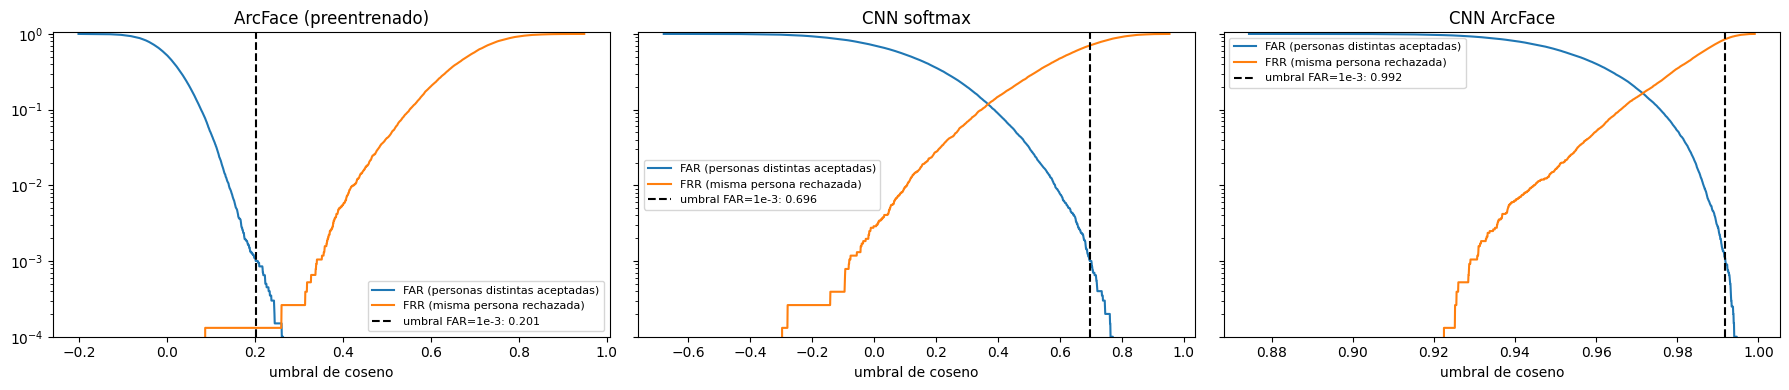

In [21]:
# FAR y FRR en función del umbral en lfw_val, con el umbral elegido de cada modelo
fig, ejes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 4), sharey=True)
for eje, modelo in zip(ejes, emb):
    candidatos, far, frr = umbrales[modelo]["curva"]
    eje.plot(candidatos, far, label="FAR (personas distintas aceptadas)")
    eje.plot(candidatos, frr, label="FRR (misma persona rechazada)")
    eje.axvline(umbrales[modelo]["umbral FAR=1e-3"], color="black", ls="--", label=f"umbral FAR=1e-3: {umbrales[modelo]['umbral FAR=1e-3']:.3f}")
    eje.set(title=modelo, xlabel="umbral de coseno", yscale="log", ylim=(1e-4, 1.05)); eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Figura 4. Tasa de falsos positivos (FAR) y de falsos negativos (FRR) en función del umbral, en `lfw_val`, con el umbral elegido de cada modelo.*

In [22]:
# El umbral calibrado en validación, aplicado en los conjuntos de test: FAR y FRR reales
filas_u = []
for modelo in emb:
    u = umbrales[modelo]["umbral FAR=1e-3"]
    for conjunto in ["lfw_val", "pins_test", "lfw_test"]:
        _, _, y = pares[conjunto]
        s = puntajes[modelo, conjunto]
        filas_u.append({"modelo": modelo, "conjunto": conjunto, "umbral": u, "FAR": (s[y == 0] >= u).mean(), "FRR": (s[y == 1] < u).mean()})
pd.DataFrame(filas_u).set_index(["modelo", "conjunto"]).round(4)

umbral     FAR     FRR
modelo                 conjunto                         
ArcFace (preentrenado) lfw_val    0.2014  0.0010  0.0001
                       pins_test  0.2014  0.0033  0.0013
                       lfw_test   0.2014  0.0010  0.0010
CNN softmax            lfw_val    0.6963  0.0010  0.7032
                       pins_test  0.6963  0.0004  0.9013
                       lfw_test   0.6963  0.0010  0.7077
CNN ArcFace            lfw_val    0.9919  0.0010  0.8544
                       pins_test  0.9919  0.0014  0.9560
                       lfw_test   0.9919  0.0010  0.8557

Para ArcFace, el umbral que deja pasar 1 de cada 1.000 pares de personas distintas en `lfw_val` es 0,201, con un FRR de 0,0001: casi no rechaza pares de la misma persona. El umbral del EER, el control, es parecido (0,245). Aplicado en test, el FAR se mantiene en 0,0010 en `lfw_test` y sube a 0,0033 en `pins_test`, donde las personas se parecen más entre sí: el umbral calibrado en LFW queda algo permisivo para fotos como las de Pins. El 0,55 que trae la app por defecto está muy por encima: la distribución de la misma persona empieza cerca de 0,3 (Figura 3), así que con 0,55 una parte de las fotos de personas registradas saldría `unknown`, sin ganar nada en falsos positivos, que ya son mínimos con 0,201. Para las CNN, el mismo criterio exige umbrales de 0,696 (softmax) y 0,992 (ArcFace), y con ellos rechazan el 70,3% y el 85,4% de los pares de la misma persona en validación (Figura 4): para tener pocos falsos positivos, tienen que rechazar a la mayoría de la gente registrada.

## Identificación

La identificación imita la app: de cada persona conocida se registran 3 fotos en una galería (como tres `/insert`), y cada foto de consulta se compara con todos los registros; la identidad es la del registro más parecido, igual que en `identify`. Con el umbral calibrado, si el mejor coseno queda por debajo, la respuesta es `unknown`. En `lfw_test` son conocidas las personas con 4 o más fotos, y desconocidas las que tienen una sola. En `pins_test`, 10 de las 15 personas son conocidas y 5 se dejan afuera de la galería como desconocidas. Top-1 y Top-5 se miden sobre las consultas de personas conocidas, sin umbral. Precisión, recall y F1 (macro) se miden con umbral, contando `unknown` como una clase más.

In [23]:
# Galería (3 fotos por persona conocida) y consultas de cada conjunto de test
FOTOS_GALERIA = 3
DESCONOCIDAS_PINS = 5
rng_gal = np.random.default_rng(SEMILLA)

def armar_galeria(conjunto):
    """Índices de galería, de consultas y la identidad real de cada consulta (unknown si la persona no está en la galería)."""
    filas = evaluacion[evaluacion["split"] == conjunto]
    tamanos = filas.groupby("persona").size()
    if conjunto == "pins_test":
        desconocidas = set(rng_gal.choice(sorted(tamanos.index), DESCONOCIDAS_PINS, replace=False))
        conocidas = [p for p in sorted(tamanos.index) if p not in desconocidas]
    else:
        desconocidas = set(tamanos[tamanos == 1].index)
        conocidas = sorted(tamanos[tamanos > FOTOS_GALERIA].index)
    galeria, consultas, verdad = [], [], []
    for persona, g in filas.groupby("persona"):
        indices = rng_gal.permutation(g.index.to_numpy())
        if persona in conocidas:
            galeria += [(i, persona) for i in indices[:FOTOS_GALERIA]]
            consultas += list(indices[FOTOS_GALERIA:]); verdad += [persona] * (len(indices) - FOTOS_GALERIA)
        elif persona in desconocidas:
            consultas += list(indices); verdad += ["unknown"] * len(indices)
    return np.array([i for i, _ in galeria]), np.array([p for _, p in galeria]), np.array(consultas), np.array(verdad)

galerias = {c: armar_galeria(c) for c in ["pins_test", "lfw_test"]}
pd.DataFrame({c: {"personas en galería": len(set(gp)), "fotos en galería": len(gi), "consultas de conocidas": int((v != "unknown").sum()), "consultas de desconocidas": int((v == "unknown").sum())} for c, (gi, gp, q, v) in galerias.items()}).T

,personas en galería,fotos en galería,consultas de conocidas,consultas de desconocidas
pins_test,10,30,1369,836
lfw_test,282,846,1958,2009


In [24]:
# Top-1 y Top-5 (conocidas, sin umbral), y precisión, recall y F1 macro con el umbral calibrado, más el rechazo de desconocidas
from sklearn.metrics import precision_recall_fscore_support
filas_id, predicciones = [], {}
for modelo, e in emb.items():
    for conjunto, (gi, gp, q, verdad) in galerias.items():
        sim = e[q] @ e[gi].T
        personas_gal = np.unique(gp)
        por_persona = np.stack([sim[:, gp == p].max(axis=1) for p in personas_gal], axis=1)
        orden = np.argsort(-por_persona, axis=1)
        conocida = verdad != "unknown"
        top1 = (personas_gal[orden[conocida, 0]] == verdad[conocida]).mean()
        top5 = np.mean([v in personas_gal[o[:5]] for v, o in zip(verdad[conocida], orden[conocida])])
        mejor = por_persona.max(axis=1)
        prediccion = np.where(mejor >= umbrales[modelo]["umbral FAR=1e-3"], personas_gal[orden[:, 0]], "unknown")
        predicciones[modelo, conjunto] = prediccion
        p, r, f, _ = precision_recall_fscore_support(verdad, prediccion, average="macro", zero_division=0)
        filas_id.append({"modelo": modelo, "conjunto": conjunto, "Top-1": top1, "Top-5": top5, "precisión macro": p, "recall macro": r, "F1 macro": f,
                         "desconocidas rechazadas": (prediccion[~conocida] == "unknown").mean(), "conocidas rechazadas": (prediccion[conocida] == "unknown").mean(),
                         "azar Top-1": 1 / len(personas_gal)})
identificacion = pd.DataFrame(filas_id).set_index(["conjunto", "modelo"]).sort_index()
identificacion.round(4)

Top-1   Top-5  precisión macro  \
conjunto  modelo                                                    
lfw_test  ArcFace (preentrenado)  1.0000  1.0000           0.5637   
          CNN ArcFace             0.3136  0.5797           0.2111   
          CNN softmax             0.5689  0.7891           0.4161   
pins_test ArcFace (preentrenado)  0.9993  1.0000           0.9729   
          CNN ArcFace             0.6399  0.9752           0.7803   
          CNN softmax             0.8101  0.9920           0.9185   

                                  recall macro  F1 macro  \
conjunto  modelo                                           
lfw_test  ArcFace (preentrenado)        0.9985    0.6808   
          CNN ArcFace                   0.2583    0.1807   
          CNN softmax                   0.4771    0.3786   
pins_test ArcFace (preentrenado)        0.9944    0.9822   
          CNN ArcFace                   0.1910    0.2250   
          CNN softmax                   0.2654    0.3066   

                                  desconocidas rechazadas  \
conjunto  modelo                                            
lfw_test  ArcFace (preentrenado)                   0.5620   
          CNN ArcFace                              0.5963   
          CNN softmax                              0.6939   
pins_test ArcFace (preentrenado)                   0.9545   
          CNN ArcFace                              0.9749   
          CNN softmax                              0.9976   

                                  conocidas rechazadas  azar Top-1  
conjunto  modelo                                                    
lfw_test  ArcFace (preentrenado)                0.0000      0.0035  
          CNN ArcFace                           0.4193      0.0035  
          CNN softmax                           0.3585      0.0035  
pins_test ArcFace (preentrenado)                0.0015      0.1000  
          CNN ArcFace                           0.8904      0.1000  
          CNN softmax                           0.8298      0.1000

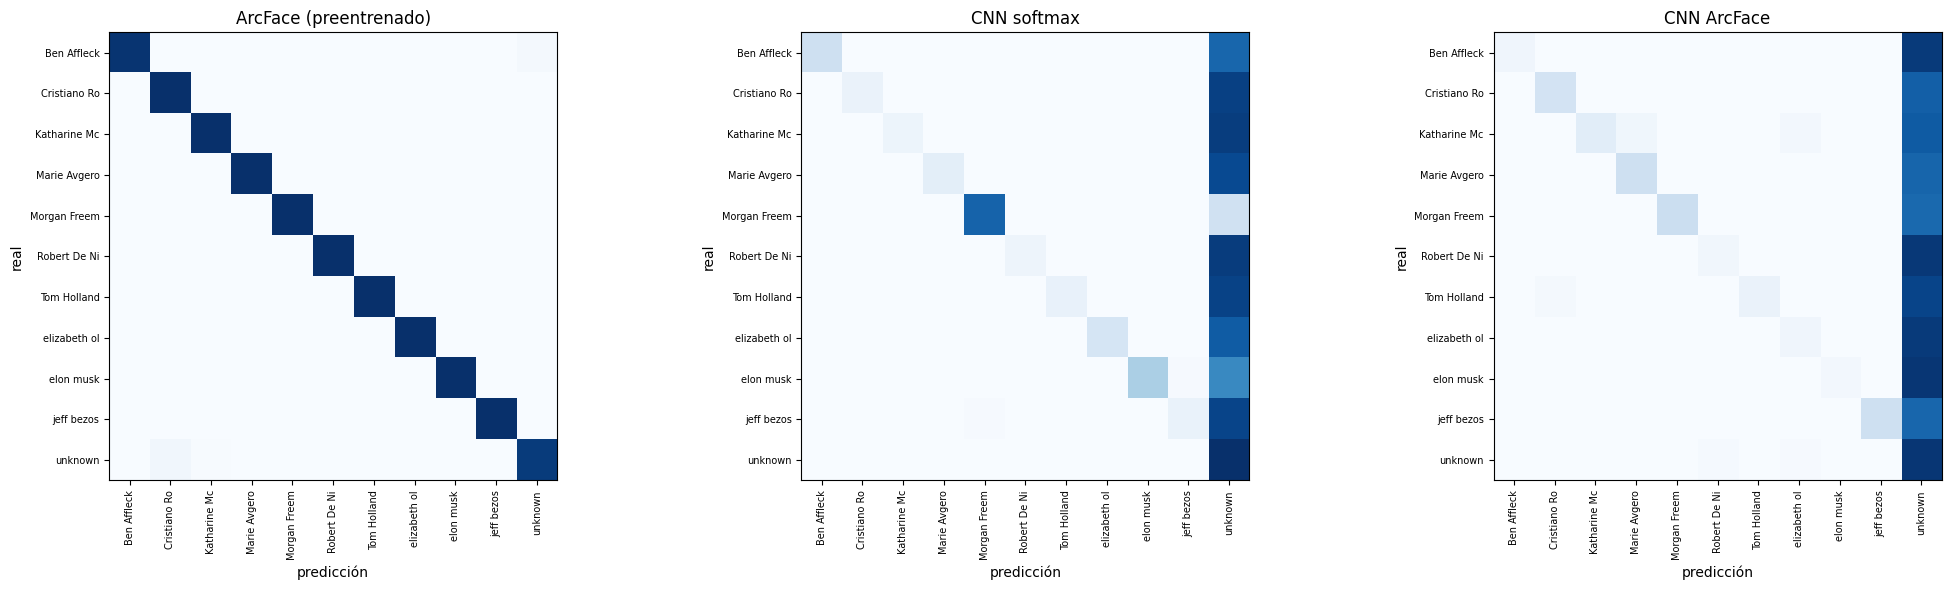

In [25]:
# Matriz de confusión en pins_test (10 personas conocidas más unknown) de cada modelo
from sklearn.metrics import confusion_matrix
_, _, _, verdad_pins = galerias["pins_test"]
etiquetas_conf = sorted(set(verdad_pins) - {"unknown"}) + ["unknown"]
fig, ejes = plt.subplots(1, len(emb), figsize=(7 * len(emb), 6))
for eje, modelo in zip(ejes, emb):
    matriz = confusion_matrix(verdad_pins, predicciones[modelo, "pins_test"], labels=etiquetas_conf, normalize="true")
    eje.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
    eje.set(title=modelo, xticks=range(len(etiquetas_conf)), yticks=range(len(etiquetas_conf)), xlabel="predicción", ylabel="real")
    eje.set_xticklabels([e[:12] for e in etiquetas_conf], rotation=90, fontsize=7); eje.set_yticklabels([e[:12] for e in etiquetas_conf], fontsize=7)
plt.tight_layout()
plt.show()

*Figura 5. Matriz de confusión normalizada por fila en `pins_test` (10 personas conocidas y `unknown`), con el umbral calibrado de cada modelo.*

In [26]:
# En lfw_test hay demasiadas personas para una matriz: los pares (real, predicción) más frecuentes entre los errores de cada modelo
for modelo in emb:
    _, _, _, verdad_lfw = galerias["lfw_test"]
    pred = predicciones[modelo, "lfw_test"]
    errores = pd.Series([f"{v} -> {p}" for v, p in zip(verdad_lfw, pred) if v != p])
    print(f"{modelo}: {len(errores)} errores de {len(pred)} consultas  |  más frecuentes: {errores.value_counts().head(5).to_dict()}")

ArcFace (preentrenado): 880 errores de 3967 consultas  |  más frecuentes: {'unknown -> Hugh_Grant': 9, 'unknown -> Donald_Rumsfeld': 9, 'unknown -> Gil_de_Ferran': 8, 'unknown -> Bill_McBride': 8, 'unknown -> Paul_Tagliabue': 8}
CNN softmax: 1702 errores de 3967 consultas  |  más frecuentes: {'Luiz_Inacio_Lula_da_Silva -> unknown': 30, 'Arnold_Schwarzenegger -> unknown': 27, 'Laura_Bush -> unknown': 27, 'Hugo_Chavez -> unknown': 24, 'Juan_Carlos_Ferrero -> unknown': 22}
CNN ArcFace: 2328 errores de 3967 consultas  |  más frecuentes: {'Hugo_Chavez -> unknown': 36, 'Serena_Williams -> unknown': 35, 'Nestor_Kirchner -> unknown': 25, 'Megawati_Sukarnoputri -> unknown': 23, 'Alvaro_Uribe -> unknown': 20}


ArcFace reconoce a todas las personas conocidas de `lfw_test` (Top-1 de 1,000, contra un azar de 0,0035 con 282 personas en la galería) y a casi todas las de `pins_test` (0,999). Las CNN aciertan el 56,9% (softmax) y el 31,4% (ArcFace) en `lfw_test`: muy por encima del azar, pero lejos de ArcFace. En Top-5, la softmax llega a 0,789. En la matriz de confusión de `pins_test` (Figura 5), los errores de las CNN son casi todos rechazos (la columna `unknown`), no confusiones entre personas: cuando superan el umbral suelen acertar, pero su umbral alto rechaza a la mayoría (el 82,9% y el 89,0% de las consultas de personas conocidas en `pins_test`).

El punto débil de ArcFace es rechazar a los desconocidos en `lfw_test`: solo el 56,2% de las consultas de personas no registradas sale `unknown`, y eso baja su precisión macro a 0,564. No es una falla del umbral, sino del tamaño de la galería: cada consulta se compara con 846 fotos registradas, y aunque cada comparación tenga una chance de 1 en 1.000 de superar el umbral, la chance de que alguna lo supere es 1 − 0,999^846 ≈ 0,57. En `pins_test`, con 30 fotos en la galería, esa cuenta da 0,03, y ArcFace rechaza al 95,5% de los desconocidos. La app, con unas pocas personas registradas, está en el segundo caso. Con galerías grandes habría que calibrar el umbral para identificación (sobre la tasa de desconocidos aceptados con una galería del tamaño real), no solo para verificación.

## Clustering de los embeddings

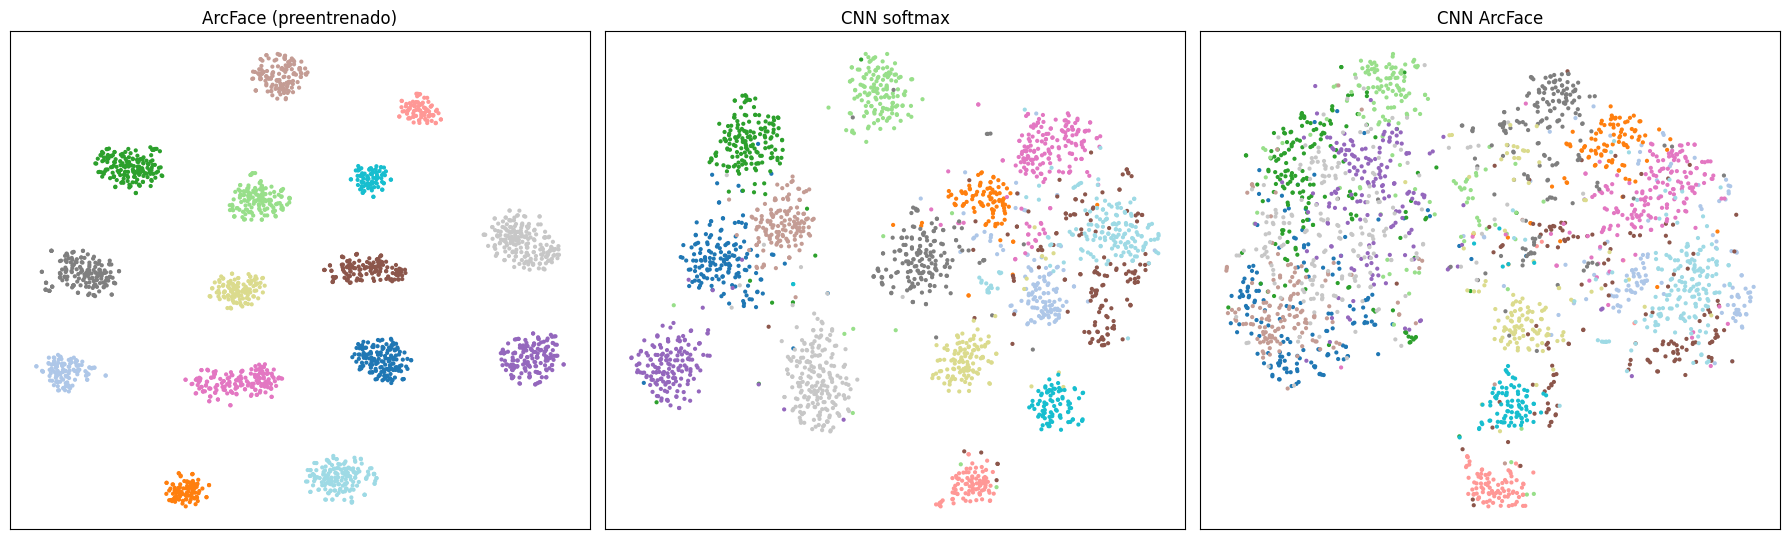

In [27]:
# t-SNE de los embeddings de pins_test de cada modelo, coloreados por persona
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
pins_eval = (evaluacion["split"] == "pins_test").to_numpy()
codigo_pins = pd.factorize(evaluacion.loc[pins_eval, "persona"])[0]
fig, ejes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 5.5))
for eje, (modelo, e) in zip(ejes, emb.items()):
    proyeccion = TSNE(2, perplexity=30, max_iter=1000, init="pca", random_state=SEMILLA).fit_transform(e[pins_eval])
    eje.scatter(*proyeccion.T, c=codigo_pins, cmap="tab20", s=4)
    eje.set(title=modelo, xticks=[], yticks=[])
plt.tight_layout()
plt.show()

*Figura 6. Proyección t-SNE de los embeddings de `pins_test` (15 personas que la CNN no vio) de cada modelo, coloreada por persona.*

In [28]:
# Silhouette (etiquetas reales) y ARI y NMI del aglomerativo en pins_test y en las personas de lfw_test con 10 o más fotos
filas_cl = []
lfw_eval = (evaluacion["split"] == "lfw_test").to_numpy() & evaluacion.groupby("persona")["persona"].transform("size").ge(10).to_numpy()
for modelo, e in emb.items():
    for conjunto, m in [("pins_test", pins_eval), ("lfw_test (10 o más fotos)", lfw_eval)]:
        etiquetas = pd.factorize(evaluacion.loc[m, "persona"])[0]
        grupos = AgglomerativeClustering(etiquetas.max() + 1, metric="cosine", linkage="average").fit_predict(e[m])
        filas_cl.append({"conjunto": conjunto, "modelo": modelo, "personas": etiquetas.max() + 1, "silhouette": silhouette_score(e[m], etiquetas, metric="cosine"),
                         "ARI": adjusted_rand_score(etiquetas, grupos), "NMI": normalized_mutual_info_score(etiquetas, grupos)})
pd.DataFrame(filas_cl).set_index(["conjunto", "modelo"]).round(3)

,,personas,silhouette,ARI,NMI
conjunto,modelo,,,,
pins_test,ArcFace (preentrenado),15,0.514,1.000,1.000
lfw_test (10 o más fotos),ArcFace (preentrenado),77,0.625,0.996,0.998
pins_test,CNN softmax,15,0.195,0.356,0.658
lfw_test (10 o más fotos),CNN softmax,77,0.172,0.368,0.772
pins_test,CNN ArcFace,15,0.077,0.225,0.485
lfw_test (10 o más fotos),CNN ArcFace,77,0.041,0.313,0.657


ArcFace agrupa a las 15 personas de `pins_test` sin un error (ARI de 1,000) y separa a las de LFW casi igual (0,996), con 15 grupos compactos y separados en la proyección (Figura 6). La CNN softmax forma grupos reconocibles pero más difusos y superpuestos (silhouette de 0,195 contra 0,514 de ArcFace, y ARI de 0,356), y la CNN ArcFace, todavía menos (ARI de 0,225). El orden coincide con el de la verificación: cuanto más compactos son los grupos de cada persona, mejor separa los pares.

## Análisis de errores

In [29]:
def mostrar_pares(indices_a, indices_b, titulos, titulo_figura):
    """Muestra pares de caras alineadas, uno debajo del otro, con un título por par."""
    fig, ejes = plt.subplots(2, len(indices_a), figsize=(1.8 * len(indices_a), 4))
    for k, (a, b) in enumerate(zip(indices_a, indices_b)):
        for fila, i in enumerate((a, b)):
            ejes[fila, k].imshow(cv2.cvtColor(cv2.imread(evaluacion.at[i, "ruta_alineada"]), cv2.COLOR_BGR2RGB)); ejes[fila, k].axis("off")
            ejes[fila, k].set_title(evaluacion.at[i, "persona"][:16] if fila == 1 else f"{titulos[k]}\n{evaluacion.at[i, 'persona'][:16]}", fontsize=7)
    fig.suptitle(titulo_figura); plt.tight_layout(); plt.show()

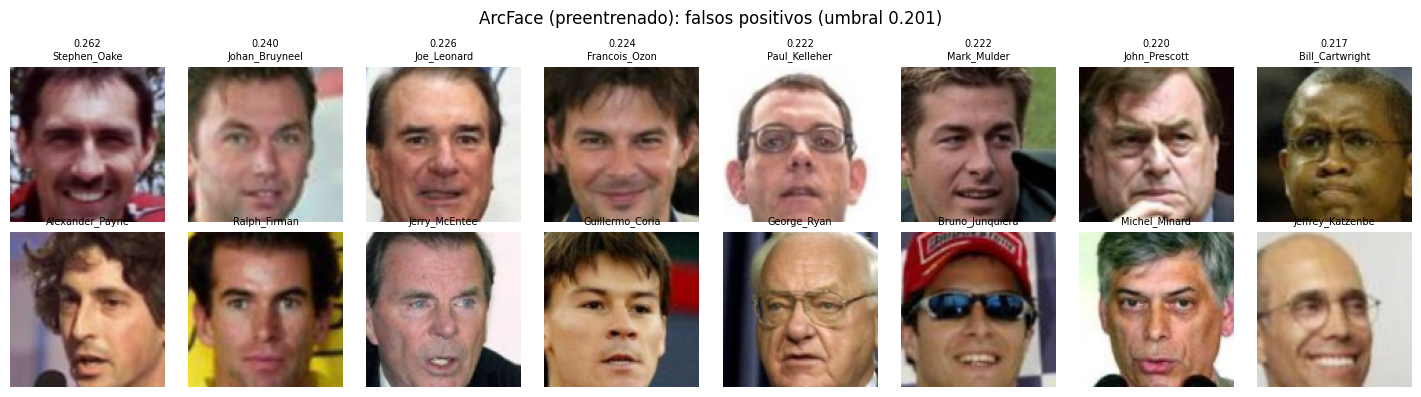

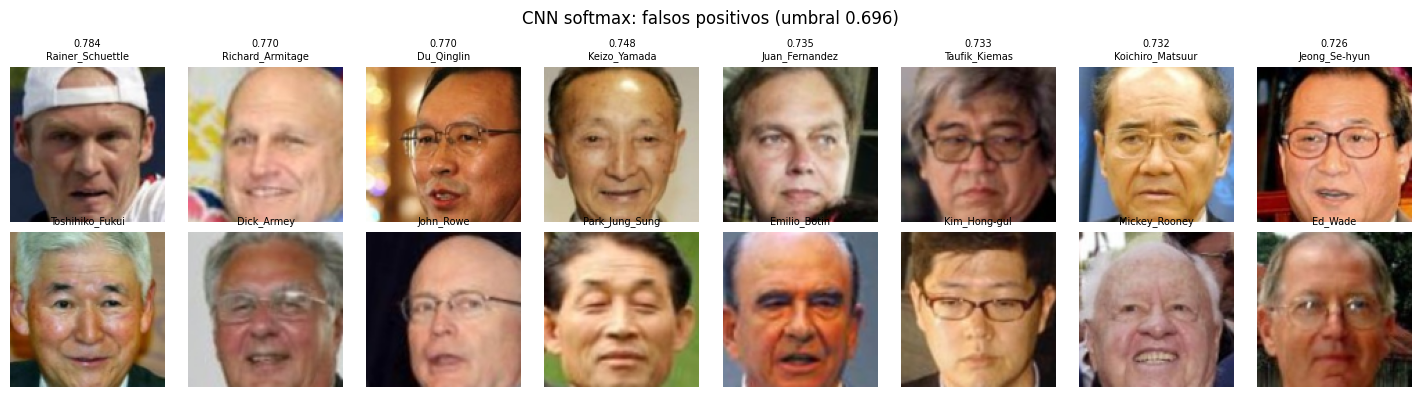

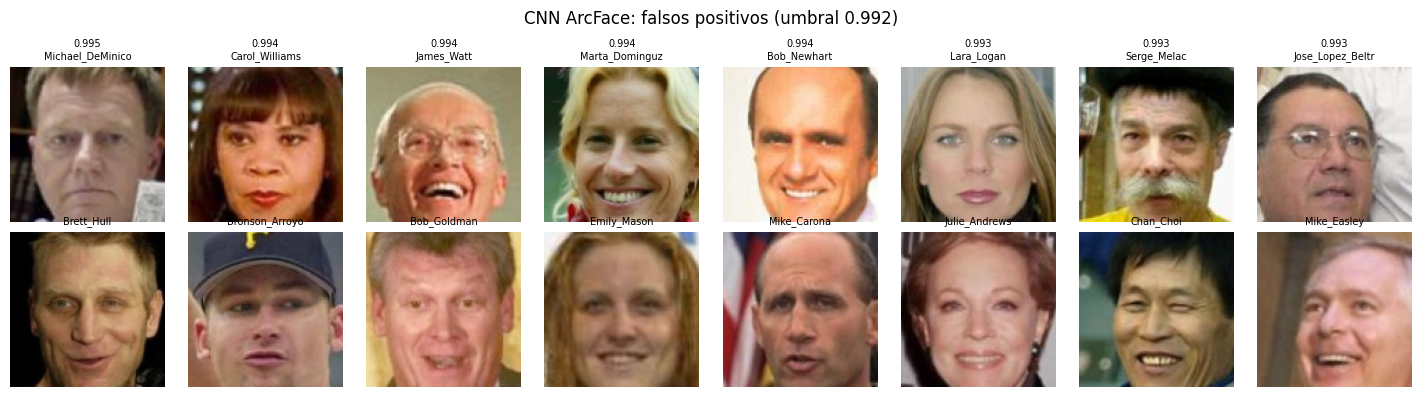

In [30]:
# Falsos positivos de cada modelo en lfw_test: los pares de personas distintas con coseno más alto
a, b, y = pares["lfw_test"]
for modelo in emb:
    s = puntajes[modelo, "lfw_test"]
    peores = np.argsort(-np.where(y == 0, s, -np.inf))[:8]
    mostrar_pares(a[peores], b[peores], [f"{s[k]:.3f}" for k in peores], f"{modelo}: falsos positivos (umbral {umbrales[modelo]['umbral FAR=1e-3']:.3f})")

*Figura 7. Los ocho pares de personas distintas con coseno más alto en `lfw_test`, para cada modelo (cada columna es un par, con el coseno arriba).*

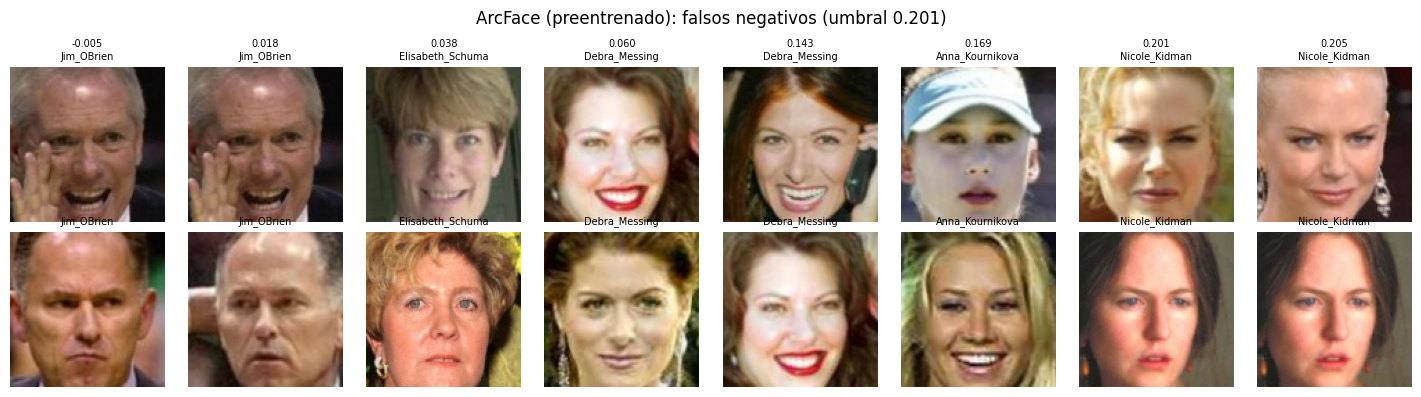

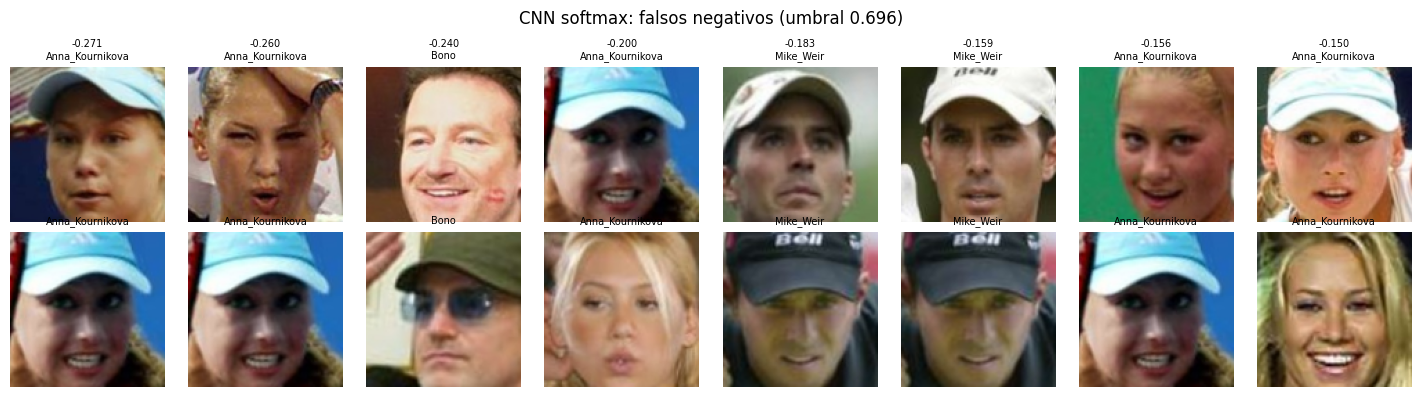

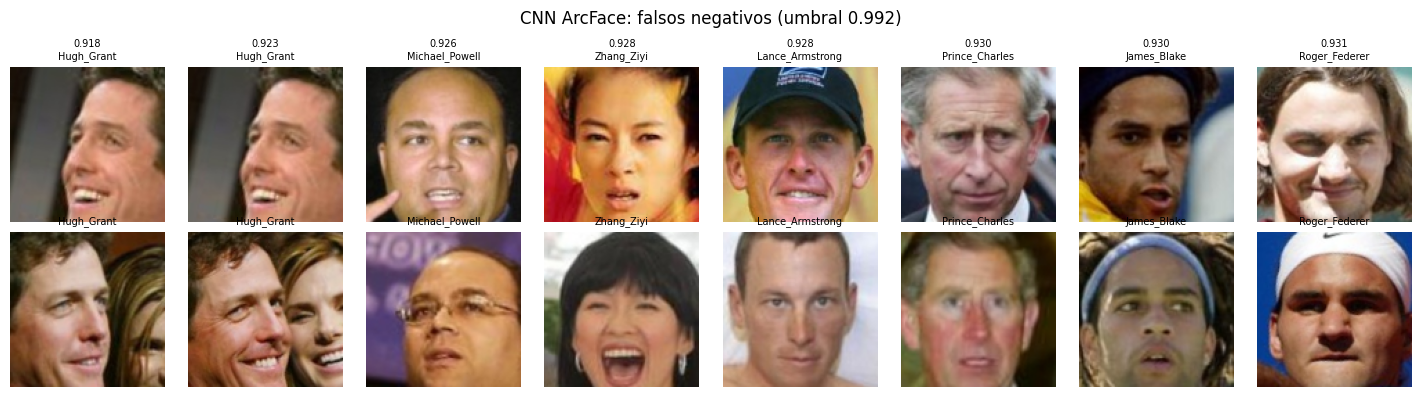

In [31]:
# Falsos negativos de cada modelo en lfw_test: los pares de la misma persona con coseno más bajo
for modelo in emb:
    s = puntajes[modelo, "lfw_test"]
    peores = np.argsort(np.where(y == 1, s, np.inf))[:8]
    mostrar_pares(a[peores], b[peores], [f"{s[k]:.3f}" for k in peores], f"{modelo}: falsos negativos (umbral {umbrales[modelo]['umbral FAR=1e-3']:.3f})")

*Figura 8. Los ocho pares de la misma persona con coseno más bajo en `lfw_test`, para cada modelo.*

Los falsos positivos de ArcFace son hombres de rasgos parecidos con cosenos de 0,22 a 0,26, apenas por encima del umbral (Figura 7). Sus peores falsos negativos no son errores del modelo, sino de las etiquetas de LFW: los pares de "Jim_OBrien", el de "Elisabeth_Schumacher" y uno de "Debra_Messing" son de dos personas distintas (Figura 8). Son caras que en la notebook 1 se marcaron como atípicas (no se parecían a nadie) y se conservaron porque no se parecían a otra persona del dataset con un coseno de 0,5 o más. Este análisis muestra que algunas eran errores de etiqueta de personas que no tienen otra foto con su nombre real. Esa decisión de la notebook 1 deja errores de etiqueta en el test, así que el error real de ArcFace es aún menor que el medido. El resto de los falsos negativos son cambios grandes de edad o de peinado (Nicole Kidman joven y adulta, con 0,201 y 0,205, justo en el umbral).

Los errores de la CNN softmax muestran qué aprendió. Sus falsos positivos son casi todos hombres mayores de origen asiático con anteojos, emparejados entre sí con cosenos de 0,73 a 0,78: la red distingue por rasgos generales (edad, origen, anteojos) más que por la identidad. Es lo esperable de una red entrenada con 90 celebridades mayormente occidentales y jóvenes, que nunca necesitó distinguir entre personas de esos grupos, y es un ejemplo concreto del sesgo que se discutió en la notebook 1. Sus falsos negativos son casi todos fotos con gorra, visera o anteojos de sol, donde la cara cambia mucho entre una foto y otra, con cosenos negativos.

## Exportación del modelo A

In [32]:
# El experimento con mayor AUC en lfw_val (criterio fijado antes de entrenar) se exporta a ONNX y se verifica que la app lo carga y da los mismos embeddings
mejor_cnn = max(["CNN softmax", "CNN ArcFace"], key=lambda m: verificacion.loc[("lfw_val", m), "AUC"])
red_elegida = {"CNN softmax": red_softmax, "CNN ArcFace": red_arcface}[mejor_cnn]
RUTA_ONNX_CNN = RUTA_MODELOS / "cnn_custom.onnx"
export_onnx(copy.deepcopy(red_elegida).cpu(), RUTA_ONNX_CNN)
servicio_cnn = FaceService(store=None, similarity_metric="cosine", similarity_threshold=0.0, face_size=112, model_path=RUTA_ONNX_CNN, output_path=RUTA_INTERMEDIOS / "servicio")
muestra = evaluacion.sample(20, random_state=SEMILLA)
desde_app = np.array([servicio_cnn.extract_embedding_from_face(AlignedFace(bbox=None, keypoints=None, image=cv2.imread(r))) for r in muestra["ruta_alineada"]])
desde_red = emb[mejor_cnn][muestra.index]
print(f"Elegido: {mejor_cnn}  |  {RUTA_ONNX_CNN} ({RUTA_ONNX_CNN.stat().st_size / 1e6:.1f} MB)  |  coseno mínimo app vs. red: {(desde_app * desde_red).sum(axis=1).min():.6f}  |  dimensión: {desde_app.shape[1]}")

Elegido: CNN softmax  |  models\cnn_custom.onnx (5.2 MB)  |  coseno mínimo app vs. red: 1.000000  |  dimensión: 512


## Costo computacional

In [33]:
def tiempo_cpu(ruta):
    """Mediana en ms de una inferencia de una cara en CPU con onnxruntime."""
    sesion = ort.InferenceSession(str(ruta), providers=["CPUExecutionProvider"])
    entrada = {sesion.get_inputs()[0].name: FaceService.preprocess_face(cv2.imread(evaluacion.at[0, "ruta_alineada"]))}
    for _ in range(10):
        sesion.run(None, entrada)
    tiempos = []
    for _ in range(100):
        inicio = time.perf_counter(); sesion.run(None, entrada); tiempos.append(1000 * (time.perf_counter() - inicio))
    return np.median(tiempos)

In [34]:
# Tamaño, parámetros y tiempo de inferencia por cara en CPU (donde corre la app): 10 llamadas de calentamiento y la mediana de 100
import onnx
costo = pd.DataFrame({
    "ArcFace (preentrenado)": {"archivo": CONFIG_APP["MODEL_NAME"], "MB": (RUTA_MODELOS / CONFIG_APP["MODEL_NAME"]).stat().st_size / 1e6,
                               "parámetros (millones)": sum(np.prod(t.dims) for t in onnx.load(str(RUTA_MODELOS / CONFIG_APP["MODEL_NAME"])).graph.initializer) / 1e6,
                               "ms por cara (CPU)": tiempo_cpu(RUTA_MODELOS / CONFIG_APP["MODEL_NAME"]), "dimensión": EMBEDDING_DIM},
    f"CNN custom ({mejor_cnn})": {"archivo": RUTA_ONNX_CNN.name, "MB": RUTA_ONNX_CNN.stat().st_size / 1e6, "parámetros (millones)": parametros / 1e6,
                                  "ms por cara (CPU)": tiempo_cpu(RUTA_ONNX_CNN), "dimensión": EMBEDDING_DIM},
}).T
costo

,archivo,MB,parámetros (millones),ms por cara (CPU),dimensión
ArcFace (preentrenado),w600k_r50.onnx,174.38386,43.590976,64.9905,512
CNN custom (CNN softmax),cnn_custom.onnx,5.227455,1.305312,3.78965,512


ArcFace pesa 174 MB y tiene 43,6 millones de parámetros, contra 5,2 MB y 1,3 millones de la CNN: es 33 veces más grande. En CPU tarda 65,0 ms por cara, contra 3,8 ms de la CNN, 17 veces más. Los dos tiempos se midieron en la CPU de la máquina donde se ejecutó esta notebook; en otra notebook más modesta, ArcFace tardó 151 ms por cara. Para la app, que procesa una foto por pedido en segundo plano, 65 a 150 ms por cara es un costo aceptable. Los dos devuelven un embedding de 512 dimensiones, así que cambiar de modelo no cambia `EMBEDDING_DIM` ni la tabla de pgvector.

## Comparación y elección

In [35]:
# Tabla comparativa de los modelos con las métricas de test (lfw_test, el escenario de la app, y pins_test, el mismo dominio que el entrenamiento)
comparacion = pd.concat({
    "verificación lfw_test": verificacion.xs("lfw_test")[["AUC", "EER", "TAR@FAR=1e-3"]],
    "verificación pins_test": verificacion.xs("pins_test")[["AUC", "EER", "TAR@FAR=1e-3"]],
    "identificación lfw_test": identificacion.xs("lfw_test")[["Top-1", "Top-5", "precisión macro", "recall macro", "F1 macro", "desconocidas rechazadas"]],
}, axis=1)
comparacion[("umbral", "FAR=1e-3 en lfw_val")] = pd.Series({m: d["umbral FAR=1e-3"] for m, d in umbrales.items()})
comparacion.round(4)

verificación lfw_test                       \
                                         AUC     EER TAR@FAR=1e-3   
modelo                                                              
ArcFace (preentrenado)                0.9998  0.0010       0.9992   
CNN ArcFace                           0.9070  0.1731       0.1423   
CNN softmax                           0.9479  0.1228       0.3011   

                       verificación pins_test                       \
                                          AUC     EER TAR@FAR=1e-3   
modelo                                                               
ArcFace (preentrenado)                 0.9999  0.0026       0.9920   
CNN ArcFace                            0.8725  0.2063       0.0360   
CNN softmax                            0.9238  0.1534       0.1347   

                       identificación lfw_test                          \
                                         Top-1   Top-5 precisión macro   
modelo                                                                   
ArcFace (preentrenado)                  1.0000  1.0000          0.5637   
CNN ArcFace                             0.3136  0.5797          0.2111   
CNN softmax                             0.5689  0.7891          0.4161   

                                                                      \
                       recall macro F1 macro desconocidas rechazadas   
modelo                                                                 
ArcFace (preentrenado)       0.9985   0.6808                  0.5620   
CNN ArcFace                  0.2583   0.1807                  0.5963   
CNN softmax                  0.4771   0.3786                  0.6939   

                                    umbral  
                       FAR=1e-3 en lfw_val  
modelo                                      
ArcFace (preentrenado)              0.2014  
CNN ArcFace                         0.9919  
CNN softmax                         0.6963

| Experimento | Épocas | Mejor acierto en validación (época) | AUC en `lfw_val` |
|---|---|---|---|
| CNN + softmax | 40 | 0,937 (40) | 0,953 |
| CNN + ArcFace (s = 64, m = 0,5) | 40 | 0,486 (39) | 0,915 |

Entre las dos CNN, el criterio fijado antes de entrenar (el mayor AUC en `lfw_val`) eligió la softmax, que es la que se exportó a ONNX.

Para la app se elige **ArcFace preentrenado**. Es mejor en todas las métricas de calidad: AUC de 0,9998 contra 0,948 en `lfw_test`, un TAR de 0,999 contra 0,301 con FAR = 1e-3, y un Top-1 de 1,000 contra 0,569. Con el umbral calibrado, rechaza el 0,01% de los pares de la misma persona, contra el 70,3% de la CNN. Su costo (174 MB y 65 a 150 ms por cara en CPU) es aceptable para la app. Ya es el modelo que el repo trae por defecto (`MODEL_NAME=w600k_r50.onnx`), así que integrarlo no cambia nada del código. Su licencia es no comercial y de investigación, que alcanza para este trabajo académico pero no para un producto. El único cambio es el umbral: `SIMILARITY_THRESHOLD` pasa de 0,55 a **0,201** (el de FAR = 1e-3 en `lfw_val`, con la métrica coseno).

La CNN custom rinde mucho menos por cuatro razones, de mayor a menor peso según lo que muestran los datos. Primero, los datos: aprendió de 90 personas y unas 12.400 caras, contra las cerca de 600.000 personas con las que se entrenó ArcFace, y por eso aprende rasgos generales (edad, origen, anteojos) en lugar de identidades (Figura 7). Segundo, la capacidad: 1,3 millones de parámetros contra 43,6 millones. Tercero, la pérdida: la softmax solo obliga a separar a las 90 personas de entrenamiento, no a dejar márgenes entre personas nuevas, y la cabeza ArcFace, que sí lo hace, quedó subentrenada con s = 64. Cuarto, el sesgo de los datos de entrenamiento, que se nota en los falsos positivos. La CNN rinde peor en Pins que en LFW, así que el cambio de dominio no está entre las causas principales. Con más épocas, una escala menor o un calentamiento con softmax, la cabeza ArcFace probablemente mejoraría, pero difícilmente alcanzaría a un modelo entrenado con 6.000 veces más personas.